In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
from FK_Multi import FK_Multi
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

## Procedure
1. `bash ../start_arm.sh`, then `python3 ../VMC/GUI_MultiVMC_Torque.py`, then
   `python3 ../VMC/GUI_MultiVMC.py`
2. Set the config to use 3 linear springs.
3. In the GUI:
   - Set spring1 to k=300, all others to k=0.
   - Move spring1 to x=0.4, z=0.21 (configuration 1).
   - Move spring2, spring3 to x=0.4, z=0.21.
   - Set k=70 for spring2, spring3 (configuration 2).
   - (Gaussian case: also move the gaussian to x=-0.1 and set k=400.)

# Three Springs vs One — Before/After Activation (x-z plane)

Experiment (using **filtered.npz**, all samples with t ≥ 400 s):

- **3 linear springs** along the robot body. The tip spring `lin_seg3` (s=1.0) is held
  at **k=300** the whole time.
- The two body springs `lin_seg2` (s=0.667) and `lin_seg_middle` (s=0.5) start at
  **k=0** and are switched to **k=70** at a single transition.
- Motion is purely along **x** (y ≈ 0), so we visualise the robot in the **x-z plane**.

We compare the robot's posture **5 s before** the k=0→70 transition (blue) against the
settled posture **5 s after** (red), on the same axes. No intermediate trajectory is shown.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

d       = np.load("outputs/three_spring_vs_one/filtered.npz", allow_pickle=True)
t       = d["t"]
k       = d["k_params"]          # (n, 3) stiffness per component
cp      = d["comp_pos"]          # (n, 3, 3) measured pos per component (x,y,z)
q_motor = d["q_motor"]           # (n, 9) motor angles, for the dense PCC curve
goal    = d["goal"]              # (n, 3, 3) each spring's reference point
names   = [str(s) for s in d["comp_names"]]
s_param = d["comp_s_params"]

# ── Find the k=0 -> 70 transition of the two body springs (component 1) ──
kc = k[:, 1]
trans_idx = np.where((kc[:-1] < 30) & (kc[1:] >= 30))[0][0] + 1
t_trans = t[trans_idx]
print(f"Components: {names}  (s={list(np.round(s_param,3))})")
print(f"Transition k=0->70 at t = {t_trans:.2f} s")
print(f"Tip spring '{names[0]}' k unique: {np.round(np.unique(k[:,0]), 1)}")
print(f"Body springs k unique: {np.round(np.unique(k[:,1]), 1)}, {np.round(np.unique(k[:,2]), 1)}")


Components: ['lin_seg3', 'lin_seg2', 'lin_seg_middle']  (s=[np.float64(1.0), np.float64(0.667), np.float64(0.5)])
Transition k=0->70 at t = 415.46 s
Tip spring 'lin_seg3' k unique: [33.3]
Body springs k unique: [ 0.  66.7], [ 0.  66.7]


## Before / after postures

For each phase we average the measured positions over a settled window:
- **Before** — the 5 s leading up to the transition (already at rest).
- **After**  — the tail of the 5 s following the transition (settled at the new posture).

The robot backbone is drawn base → `lin_seg_middle` → `lin_seg2` → `lin_seg3` (tip),
ordered by s-parameter.

In [3]:
HALF = 5.0   # seconds before/after the transition to consider

def mean_raw(arr, t_lo, t_hi):
    """Mean of a (n, ...) array over [t_lo, t_hi), in the file's own component order."""
    m = (t >= t_lo) & (t < t_hi)
    return arr[m].mean(axis=0)

def mean_pose(t_lo, t_hi):
    """Mean (x,z) of each component over [t_lo, t_hi); returns backbone incl. base."""
    pts = mean_raw(cp, t_lo, t_hi)       # (3, 3) -> mean x,y,z per component
    order = np.argsort(s_param)         # base..tip by s
    xz = np.column_stack([pts[order, 0], pts[order, 2]])   # (3, 2) -> (x, z)
    base = np.array([[0.0, 0.0]])       # robot root at origin
    return np.vstack([base, xz])        # (4, 2)

# Before: full 5 s pre-transition (settled).  After: last 1.5 s of the 5 s window (settled).
before = mean_pose(t_trans - HALF, t_trans)
after  = mean_pose(t_trans + HALF - 1.5, t_trans + HALF)

# Full 9-DOF pose and each spring's raw (unsorted) attach/goal point, for the
# dense PCC backbone and the dashed spring-connector lines.
q_before        = mean_raw(q_motor, t_trans - HALF, t_trans)
q_after         = mean_raw(q_motor, t_trans + HALF - 1.5, t_trans + HALF)
cp_before_raw   = mean_raw(cp,   t_trans - HALF, t_trans)
cp_after_raw    = mean_raw(cp,   t_trans + HALF - 1.5, t_trans + HALF)
goal_before_raw = mean_raw(goal, t_trans - HALF, t_trans)
goal_after_raw  = mean_raw(goal, t_trans + HALF - 1.5, t_trans + HALF)

print("Backbone (x, z)  [base, middle, seg2, tip]")
print("BEFORE:\n", np.round(before, 4))
print("AFTER :\n", np.round(after, 4))


Backbone (x, z)  [base, middle, seg2, tip]
BEFORE:
 [[0.     0.    ]
 [0.0654 0.1694]
 [0.1441 0.2461]
 [0.2698 0.3195]]
AFTER :
 [[0.     0.    ]
 [0.1103 0.1469]
 [0.2142 0.1901]
 [0.354  0.2265]]


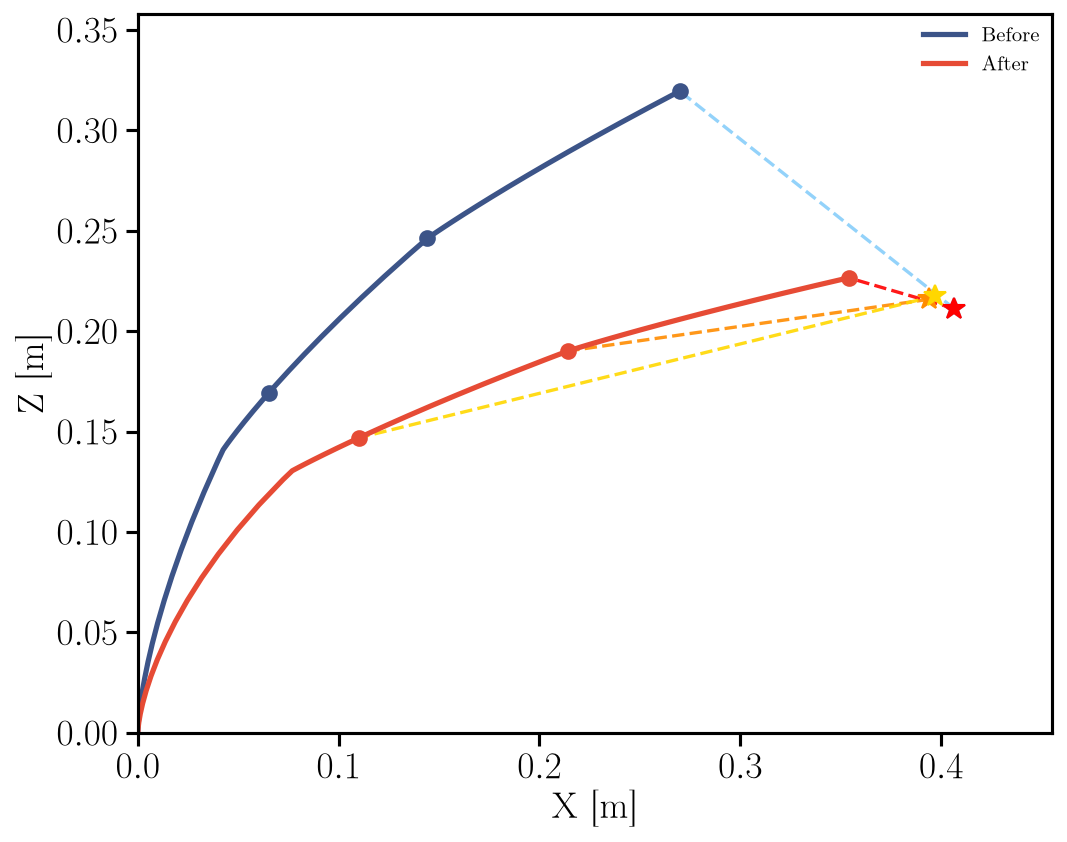

Before: lin_seg3 k=30 N/m (others 0)
After:  lin_seg3 k=30 N/m, lin_seg2 k=70 N/m, lin_seg_middle k=70 N/m
Saved filtered.png


In [4]:
SHOW_SPRINGS = True   # dashed lines from each active spring's goal to its attachment point
K_ACTIVE = 1.0         # [N/m] below this a spring counts as off (k=0) and isn't drawn
# After: a warm gradient along the arm's length, base -> tip -- lin_seg_middle
# (s=.5) gold, lin_seg2 (s=.667) orange, lin_seg3 the tip (s=1.0) red, "hotter"
# closer to the tip. Before has only the one spring (lin_seg3), so it just gets
# its own light blue instead of joining that gradient.
# names/raw order is [lin_seg3, lin_seg2, lin_seg_middle], so:
SPRING_COLORS_AFTER = ['red', 'darkorange', 'gold']
SPRING_COLOR_BEFORE = 'lightskyblue'

def round10(v):
    """The nominal design stiffness (30, 70, ...) instead of what actually got
    logged (33.3, 66.7, ...)."""
    return int(round(v / 10.0) * 10)

S_DENSE = np.linspace(0.0, 1.0, 50)

def pcc_backbone_xz(q):
    """The true continuous PCC shape (x-z plane), base -> tip -- not just the
    3 named attachment points connected by straight segments."""
    pts = np.array([FK_Multi(q, s)[:3] for s in S_DENSE])
    return np.vstack([[0.0, 0.0, 0.0], pts])[:, [0, 2]]


k_before_raw = mean_raw(k, t_trans - HALF, t_trans)
k_after_raw  = mean_raw(k, t_trans + HALF - 1.5, t_trans + HALF)

curve_before = pcc_backbone_xz(q_before)
curve_after  = pcc_backbone_xz(q_after)

# (curve, per-component attach point, per-component goal, per-component k,
#  state colour, legend label, per-component spring colours)
states = [(curve_before, cp_before_raw, goal_before_raw, k_before_raw, COLORS[3], "Before",
          [SPRING_COLOR_BEFORE] * len(names)),
         (curve_after,  cp_after_raw,  goal_after_raw,  k_after_raw,  COLORS[1], "After",
          SPRING_COLORS_AFTER)]

# Data extent -- both curves and every ACTIVE spring's goal -- pinned to (0, 0)
# at the low end (the robot's base), padded only on the high end.
goal_pts = [(g[ci, 0], g[ci, 2]) for _, _, g, kr, _, _, _ in states
           for ci in range(len(names)) if kr[ci] > K_ACTIVE]
all_x = np.concatenate([curve_before[:, 0], curve_after[:, 0], [0.0]] + [[gx] for gx, gz in goal_pts])
all_z = np.concatenate([curve_before[:, 1], curve_after[:, 1], [0.0]] + [[gz] for gx, gz in goal_pts])
xlim = (0.0, all_x.max() * 1.12)
zlim = (0.0, all_z.max() * 1.12)

# ---- size / aspect for THIS graph only ----
W_IN = 7.0   # inches -- width; the deliberate choice, so the fixed 18pt font reads
             # at the intended size once this is fixed. Height follows from the
             # data's true x-z aspect ratio so the equal-scale drawing isn't distorted.
H_IN = W_IN * (zlim[1] - zlim[0]) / (xlim[1] - xlim[0])
fig, ax = plt.subplots(figsize=(W_IN, H_IN), layout='constrained')

for curve, cp_raw, goal_raw, k_raw, color, tag, spring_colors in states:
    ax.plot(curve[:, 0], curve[:, 1], "-", color=color, linewidth=2.5, zorder=2, label=tag)
    ax.plot(cp_raw[:, 0], cp_raw[:, 2], "o", color=color, markersize=7, zorder=3)

    if SHOW_SPRINGS:
        for ci in range(len(names)):
            if k_raw[ci] <= K_ACTIVE:
                continue
            spring_color = spring_colors[ci]
            gx, gz = goal_raw[ci, 0], goal_raw[ci, 2]
            ax.plot([gx, cp_raw[ci, 0]], [gz, cp_raw[ci, 2]], "--",
                    color=spring_color, linewidth=1.6, alpha=0.9, zorder=1)
            ax.plot(gx, gz, "*", color=spring_color, markersize=11, zorder=4)

ax.set_xlabel("X [m]")
ax.set_ylabel("Z [m]")
ax.set_xlim(*xlim); ax.set_ylim(*zlim)
ax.set_aspect("equal")
ax.grid(GRID)
ax.legend(loc="best", fontsize=10)   # Before/After only -- spring identities are printed below
plt.savefig(os.path.join("outputs", "three_spring_vs_one", "filtered.pdf"))
plt.show()

print(f"Before: {names[0]} k={round10(k_before_raw[0])} N/m (others 0)")
active_after = [(names[ci], round10(k_after_raw[ci])) for ci in range(len(names)) if k_after_raw[ci] > K_ACTIVE]
print("After:  " + ", ".join(f"{n} k={kv} N/m" for n, kv in active_after))
print("Saved filtered.png")